In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph,END
import random

In [3]:
class AgentState(TypedDict):
    player_name : str
    target_number : int
    guesses : int
    attempts : int
    hint : str
    lower_bound : int
    upper_bound : int


In [ ]:
def setup_node(state : AgentState) -> AgentState:
    state['player_name'] = f"Welcome, {state['player_name']}"
    state['target_number'] = random.randint(1,20)
    state['guesses'] = []
    state['attempts'] = 0
    state['hint'] = "Game started! Try to guess the number."
    state['lower_bound'] = 1
    state['upper_bound'] = 20
    print(f"{state['player_name']} The game has begun. I'm thinking of a number between 1 and 20.")
    return state

In [6]:
def guess_node(state : AgentState) -> AgentState:
    possible_guesses = [i for i in range(state['lower_bound'],state['upper_bound']+1) if i not in state['guesses']]
    if possible_guesses:
        guess = random.choice(possible_guesses)
    else:
        guess = random.randint(state['lower_bound'],state['upper_bound'])
    state['guesses'].append(guess)
    state['attempts'] += 1
    print(f"Attempt {state['attempts']}: Guessing {guess} (Current range: {state['lower_bound']}-{state['upper_bound']})")
    return state

In [7]:
def hint_node(state : AgentState) -> AgentState:
    latest_guess = state['guesses'][-1]
    target = state['target_number']
    if latest_guess < target:
        state["hint"] = f"The number {latest_guess} is too low. Try higher!"
        
        state["lower_bound"] = max(state["lower_bound"], latest_guess + 1)
        print(f"Hint: {state['hint']}")
        
    elif latest_guess > target:
        state["hint"] = f"The number {latest_guess} is too high. Try lower!"
      
        state["upper_bound"] = min(state["upper_bound"], latest_guess - 1)
        print(f"Hint: {state['hint']}")
    else:
        state["hint"] = f"Correct! You found the number {target} in {state['attempts']} attempts."
        print(f"Success! {state['hint']}")
    
    return state

In [9]:
def should_continue(state: AgentState) -> str:
    """Determine if we should continue guessing or end the game"""
    
    # There are 2 end conditions - either 7 is reached or the correct number is guessed
    
    latest_guess = state["guesses"][-1]
    if latest_guess == state["target_number"]:
        print("GAME OVER: Number found!")
        return "end"
    elif state["attempts"] >= 7:
        print(f"GAME OVER: Maximum attempts reached! The number was {state['target_number']}")
        return "end"
    else:
        print(f"CONTINUING: {state['attempts']}/7 attempts used")
        return "continue"

In [10]:
game = StateGraph(AgentState)
game.add_node("setup_node",setup_node)
game.add_node("guess_node",guess_node)
game.add_node("hint_node", hint_node)
game.add_edge("setup_node","guess_node")
game.add_edge("guess_node","hint_node")
game.add_conditional_edges (
    "hint_node",
    should_continue,
    {
        "continue" : "guess_node",
        "end" : END
    }
)
game.set_entry_point("setup_node")
app = game.compile()

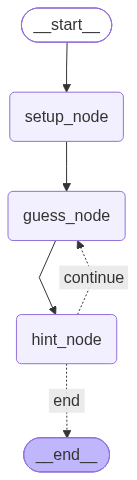

In [11]:
from IPython.display import Image,display
display(Image(app.get_graph().draw_mermaid_png()))

In [15]:
result = app.invoke({
    "player_name": "student",
    "guesses" : [],
    "attempts": 0,
    "lower_bound" : 1,
    "upper_bound":20

})

Welcome, student The game has begun. I'm thinking of a number between 1 and 20.
Attempt 1: Guessing 10 (Current range: 1-20)
Hint: The number 10 is too low. Try higher!
CONTINUING: 1/7 attempts used
Attempt 2: Guessing 14 (Current range: 11-20)
Hint: The number 14 is too low. Try higher!
CONTINUING: 2/7 attempts used
Attempt 3: Guessing 20 (Current range: 15-20)
Hint: The number 20 is too high. Try lower!
CONTINUING: 3/7 attempts used
Attempt 4: Guessing 19 (Current range: 15-19)
Hint: The number 19 is too high. Try lower!
CONTINUING: 4/7 attempts used
Attempt 5: Guessing 17 (Current range: 15-18)
Hint: The number 17 is too high. Try lower!
CONTINUING: 5/7 attempts used
Attempt 6: Guessing 16 (Current range: 15-16)
Success! Correct! You found the number 16 in 6 attempts.
GAME OVER: Number found!
